# Passaí
## Modelagem matemática de travessias acessíveis
### Differentiated Problem Solving • Modelagem Matemática Avançada

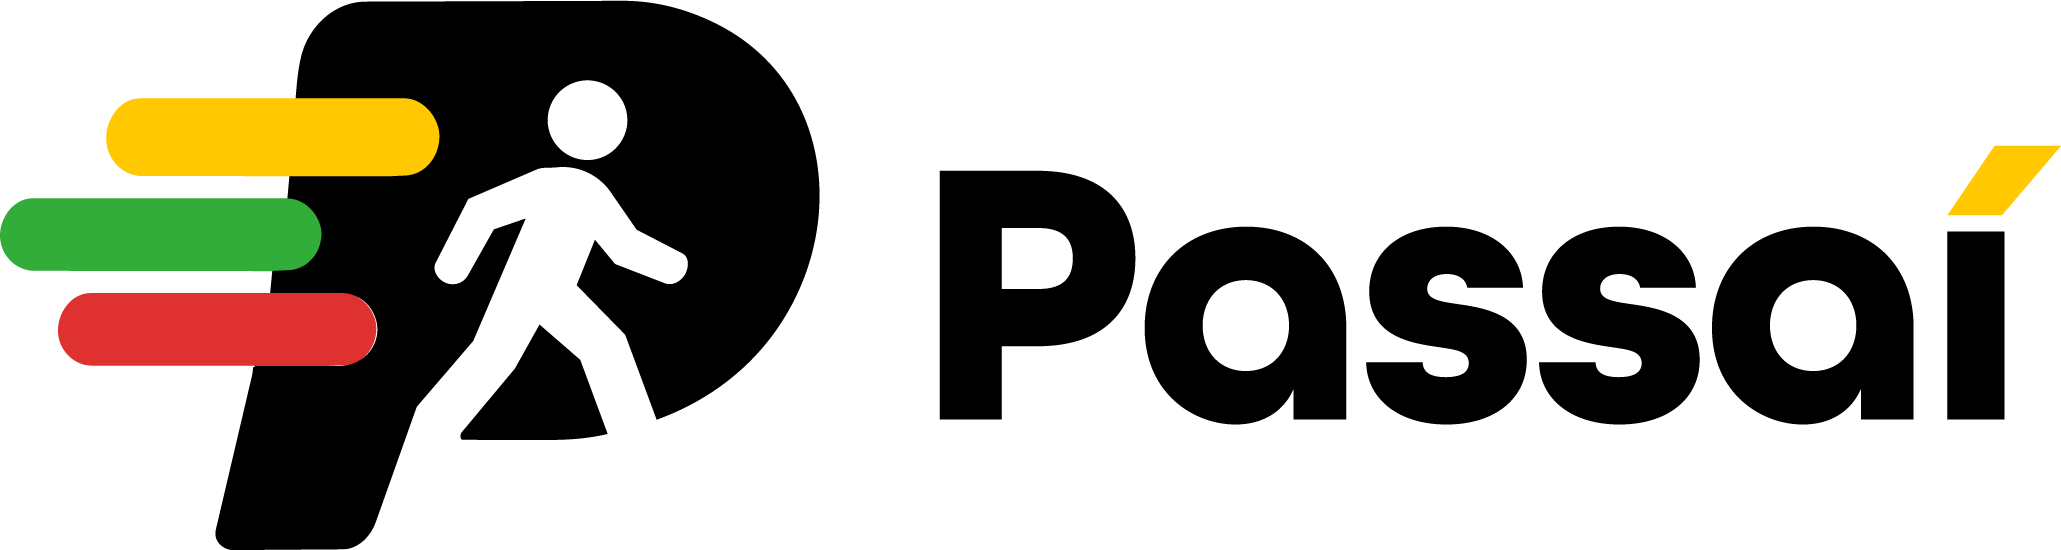

| Integrante | RM |
|:--|:--|
| Rafael Taboada Sobral | 569527 |
| Fabricio Denig De Avila | 570980 |
| Beatriz Perigo | 569654 |

**Questão orientadora:** como a largura da faixa, a velocidade de deslocamento e a extensão semafórica alteram o tempo necessário e as possibilidades de conclusão de uma travessia?

Este notebook apresenta explicação, desenvolvimento matemático, código, gráfico e interpretação em sequência. Todos os parâmetros numéricos são de um **cenário didático simulado**.

## Como utilizar este notebook

O arquivo já contém os resultados e os seis gráficos salvos nas células. Para recalcular, abra em um ambiente de notebooks com **Python 3.10 ou superior** e use **Reiniciar kernel e executar tudo**, seguindo a ordem de cima para baixo.

- **VS Code:** utilize as extensões Python e Jupyter e selecione um ambiente com `ipykernel` instalado.
- **Jupyter:** abra o arquivo em Jupyter Notebook ou JupyterLab.
- **Colab:** o notebook é autocontido; as células não fazem downloads nem dependem de arquivos locais. O acesso ao serviço em si exige internet.

Em uma instalação comum de Python, `python -m pip install ipykernel` prepara o kernel para o VS Code. Para usar JupyterLab, instale-o com `python -m pip install jupyterlab` e inicie com `python -m jupyterlab`.

O Python portátil fornecido com a versão `.py` não inclui o ambiente Jupyter. O inicializador `.bat` continua destinado ao programa original.

**Organização:** contexto e parâmetros → tempo e limites → derivadas → integral de chegadas → mapa → valor médio → otimização → conferência e conclusão.

As células de apoio visual estão marcadas para recolhimento nos leitores compatíveis. É possível expandi-las para consultar o desenho dos gráficos. Os arquivos temporários servem apenas para gerar as imagens; as pastas e arquivos originais do projeto não são sobrescritos.

## 1. Problema, objetivo e hipóteses

O Passaí nasceu da proposta Travessia, que conecta acessibilidade, organização de evidências cidadãs e um protótipo experimental de semáforo. Pedestres com velocidades diferentes podem precisar de tempos distintos para percorrer a mesma faixa.

O objetivo desta análise é aplicar limites, derivadas e integrais para comparar cenários e discutir parâmetros do protótipo. Não há medições de campo neste estudo. O programa não controla sinalização pública.

Assumimos velocidade constante, distância fixa, tempo de reação adicionado uma vez e ausência de filas, paradas ou conflitos. Na análise inicial, a pessoa parte no início da fase. Na integral das chegadas, consideramos o instante em que cada pessoa chega à travessia.

### Preparação do ambiente
Usamos a biblioteca padrão para os cálculos e a construção dos SVGs. `IPython.display` permite exibir tabelas e gráficos dentro do notebook.

In [1]:
from __future__ import annotations

import html
import math
import tempfile
from dataclasses import dataclass
from pathlib import Path
from typing import Callable, Iterable, Sequence
from IPython.display import HTML, SVG, display

# Os gráficos são gerados em uma pasta temporária exclusiva desta execução.
# Nenhum arquivo do projeto original é modificado.
temporarios = tempfile.TemporaryDirectory(prefix="passai_notebook_")
pasta_graficos = Path(temporarios.name)

def mostrar_tabela(colunas, linhas):
    """Exibe dados escapados como uma tabela legível no notebook."""
    cabecalho = "".join(f"<th>{html.escape(str(c))}</th>" for c in colunas)
    corpo = "".join("<tr>" + "".join(f"<td>{html.escape(str(v))}</td>" for v in linha) + "</tr>" for linha in linhas)
    display(HTML(f'<table class="passai-tabela"><thead><tr>{cabecalho}</tr></thead><tbody>{corpo}</tbody></table>'))

display(HTML("""<style>
.passai-tabela {border-collapse:collapse; margin:12px 0; font-size:14px;}
.passai-tabela th {background:#e5efe9; color:#164c38; text-align:left;}
.passai-tabela td,.passai-tabela th {padding:9px 14px; border-bottom:1px solid #d9e3dd;}
</style>"""))
print("Ambiente pronto. Cálculos locais; nenhum download de dados.")

Ambiente pronto. Cálculos locais; nenhum download de dados.


### Parâmetros e validações

`CenarioTravessia` reúne as grandezas e impede entradas incompatíveis com o modelo. Os tempos são expressos em segundos e a largura em metros. A velocidade é medida em m/s. Os pesos de otimização são ilustrativos.

| Símbolo | Papel | Unidade |
|:--|:--|:--|
| L; r; v | Largura, reação e velocidade | m; s; m/s |
| G; e | Tempo-base e extensão | s |
| λ₀; β | Taxa inicial e crescimento da taxa | pedestres/s; pedestres/s² |
| A; k; B | Pesos da função de custo | pontos; s⁻¹; pontos/s² |

As interpretações textuais deste notebook referem-se ao cenário padrão. Alterar valores exige reinterpretar os resultados; alguns eixos e legendas gráficas permanecem ajustados ao cenário original.

In [2]:
@dataclass(frozen=True)
class CenarioTravessia:
    """Grandezas do cenário didático e suas respectivas unidades."""

    largura_m: float = 10.0
    tempo_reacao_s: float = 2.0
    tempo_base_s: float = 12.0
    extensao_s: float = 4.0
    velocidade_referencia_m_s: float = 1.0
    taxa_inicial_ped_s: float = 0.4
    crescimento_taxa_ped_s2: float = 0.05
    peso_acessibilidade: float = 100.0
    decaimento_beneficio_s_inv: float = 0.35
    peso_impacto_viario: float = 2.0
    velocidades_m_s: tuple[float, ...] = (1.25, 1.0, 0.8, 0.6)

    def __post_init__(self) -> None:
        """Valida os parâmetros assim que um cenário é criado."""
        positivos = {
            "largura_m": self.largura_m,
            "tempo_base_s": self.tempo_base_s,
            "velocidade_referencia_m_s": self.velocidade_referencia_m_s,
            "peso_acessibilidade": self.peso_acessibilidade,
            "decaimento_beneficio_s_inv": self.decaimento_beneficio_s_inv,
            "peso_impacto_viario": self.peso_impacto_viario,
        }
        for nome, valor in positivos.items():
            if not math.isfinite(valor) or valor <= 0:
                raise ValueError(f"{nome} deve ser um número positivo.")

        nao_negativos = {
            "tempo_reacao_s": self.tempo_reacao_s,
            "extensao_s": self.extensao_s,
            "taxa_inicial_ped_s": self.taxa_inicial_ped_s,
            "crescimento_taxa_ped_s2": self.crescimento_taxa_ped_s2,
        }
        for nome, valor in nao_negativos.items():
            if not math.isfinite(valor) or valor < 0:
                raise ValueError(f"{nome} deve ser um número não negativo.")

        if self.tempo_base_s <= self.tempo_reacao_s:
            raise ValueError("O tempo-base deve superar o tempo de reação.")
        if not self.velocidades_m_s:
            raise ValueError("Informe pelo menos uma velocidade para a análise.")
        if any(not math.isfinite(v) or v <= 0 for v in self.velocidades_m_s):
            raise ValueError("Todas as velocidades devem ser positivas.")

    @property
    def tempo_estendido_s(self) -> float:
        """Soma o tempo-base e a extensão, ambos em segundos."""
        return self.tempo_base_s + self.extensao_s


@dataclass(frozen=True)
class ResultadoCenario:
    """Reúne tempo, margens e classificações de uma velocidade."""

    velocidade_m_s: float
    tempo_necessario_s: float
    margem_base_s: float
    margem_estendida_s: float
    situacao_base: str
    situacao_estendida: str
    extensao_muda_resultado: bool


def validar_janela(inicio_s: float, fim_s: float) -> None:
    """Rejeita instantes negativos ou uma janela com fim anterior ao início."""
    if not 0 <= inicio_s <= fim_s:
        raise ValueError("A janela deve obedecer 0 <= início <= fim.")


def validar_intervalo_velocidade(inicio_m_s: float, fim_m_s: float) -> None:
    """Exige velocidades finitas com 0 < início < fim."""
    if not (math.isfinite(inicio_m_s) and math.isfinite(fim_m_s)):
        raise ValueError("As velocidades devem ser finitas.")
    if not 0 < inicio_m_s < fim_m_s:
        raise ValueError("O intervalo deve obedecer 0 < velocidade inicial < velocidade final.")


def validar_extensao(extensao_s: float) -> None:
    """Exige uma extensão finita e não negativa."""
    if not math.isfinite(extensao_s) or extensao_s < 0:
        raise ValueError("A extensão deve ser não negativa e finita.")

In [3]:
cenario = CenarioTravessia()
mostrar_tabela(["Grandeza", "Valor"], [
    ["Largura", f"{cenario.largura_m:g} m"],
    ["Reação", f"{cenario.tempo_reacao_s:g} s"],
    ["Tempo-base", f"{cenario.tempo_base_s:g} s"],
    ["Extensão", f"{cenario.extensao_s:g} s"],
    ["Tempo total", f"{cenario.tempo_estendido_s:g} s"],
    ["Velocidades", str(cenario.velocidades_m_s) + " m/s"],
    ["Taxa inicial / crescimento", f"{cenario.taxa_inicial_ped_s} ped/s / {cenario.crescimento_taxa_ped_s2} ped/s²"],
    ["A / k / B", f"{cenario.peso_acessibilidade:g} / {cenario.decaimento_beneficio_s_inv:g} / {cenario.peso_impacto_viario:g}"],
])

Grandeza,Valor
Largura,10 m
Reação,2 s
Tempo-base,12 s
Extensão,4 s
Tempo total,16 s
Velocidades,"(1.25, 1.0, 0.8, 0.6) m/s"
Taxa inicial / crescimento,0.4 ped/s / 0.05 ped/s²
A / k / B,100 / 0.35 / 2


### Apoio visual compartilhado

As próximas células definem cores, coordenadas, linhas, textos e áreas. São recursos de desenho reutilizados pelos seis gráficos. As fórmulas matemáticas aparecem separadas nas seções seguintes. O desenho usa as mesmas funções da versão `.py`, preservando suas figuras.

In [4]:
COR_VINHO = "#A80F45"
COR_ROSA = "#E91E63"
COR_AZUL = "#245B78"
COR_VERDE = "#23856D"
COR_AMARELO = "#F1B24A"
COR_TEXTO = "#25242A"
COR_GRADE = "#D9D9DF"
COR_FUNDO = "#FAFAFC"
TOLERANCIA_MARGEM_S = 1e-9
LIMITE_BUSCA_EXTENSAO_S = 3600

In [5]:
@dataclass(frozen=True)
class AreaGrafico:
    """Transforma coordenadas matemáticas em posições dentro de um SVG."""

    x: float
    y: float
    largura: float
    altura: float
    x_min: float
    x_max: float
    y_min: float
    y_max: float

    def px(self, valor: float) -> float:
        """Converte uma coordenada horizontal do modelo para pixels."""
        return self.x + (valor - self.x_min) * self.largura / (self.x_max - self.x_min)

    def py(self, valor: float) -> float:
        """Inverte o eixo vertical: na imagem, os pixels crescem para baixo."""
        return self.y + self.altura - (valor - self.y_min) * self.altura / (self.y_max - self.y_min)


def valores_entre(inicio: float, fim: float, quantidade: int) -> list[float]:
    """Cria amostras igualmente espaçadas para desenhar curvas e eixos."""
    if quantidade < 2:
        return [inicio]
    passo = (fim - inicio) / (quantidade - 1)
    return [inicio + passo * indice for indice in range(quantidade)]


def texto_svg(
    x: float,
    y: float,
    conteudo: str,
    tamanho: int = 18,
    ancora: str = "middle",
    cor: str = COR_TEXTO,
    peso: str = "normal",
    rotacao: float | None = None,
) -> str:
    """Escreve um rótulo SVG, escapando caracteres especiais do texto."""
    transformacao = f' transform="rotate({rotacao} {x:.2f} {y:.2f})"' if rotacao is not None else ""
    return (
        f'<text x="{x:.2f}" y="{y:.2f}" text-anchor="{ancora}" '
        f'font-family="Arial, sans-serif" font-size="{tamanho}" fill="{cor}" '
        f'font-weight="{peso}"{transformacao}>{html.escape(conteudo)}</text>'
    )


def linha_svg(x1: float, y1: float, x2: float, y2: float, cor: str, largura: float = 2,
              tracejado: str | None = None) -> str:
    """Desenha um segmento, opcionalmente tracejado."""
    traco = f' stroke-dasharray="{tracejado}"' if tracejado else ""
    return (
        f'<line x1="{x1:.2f}" y1="{y1:.2f}" x2="{x2:.2f}" y2="{y2:.2f}" '
        f'stroke="{cor}" stroke-width="{largura}"{traco}/>'
    )


def polilinha_svg(pontos: Iterable[tuple[float, float]], cor: str, largura: float = 4) -> str:
    """Une pontos para representar uma curva sem preenchimento."""
    coordenadas = " ".join(f"{x:.2f},{y:.2f}" for x, y in pontos)
    return (
        f'<polyline points="{coordenadas}" fill="none" stroke="{cor}" '
        f'stroke-width="{largura}" stroke-linejoin="round" stroke-linecap="round"/>'
    )


def poligono_svg(pontos: Iterable[tuple[float, float]], preenchimento: str, opacidade: float = 1,
                 contorno: str = "none") -> str:
    """Fecha uma área de pontos e aplica seu preenchimento."""
    coordenadas = " ".join(f"{x:.2f},{y:.2f}" for x, y in pontos)
    return (
        f'<polygon points="{coordenadas}" fill="{preenchimento}" fill-opacity="{opacidade}" '
        f'stroke="{contorno}"/>'
    )


def circulo_svg(x: float, y: float, raio: float, cor: str, contorno: str = "white") -> str:
    """Cria um marcador para destacar um ponto da análise."""
    return (
        f'<circle cx="{x:.2f}" cy="{y:.2f}" r="{raio}" fill="{cor}" '
        f'stroke="{contorno}" stroke-width="2"/>'
    )


def criar_documento_svg(titulo: str, subtitulo: str, elementos: Sequence[str],
                        largura: int = 1200, altura: int = 760) -> str:
    """Reúne fundo, títulos e elementos em uma imagem SVG completa."""
    return "\n".join(
        [
            f'<svg xmlns="http://www.w3.org/2000/svg" width="{largura}" height="{altura}" '
            f'viewBox="0 0 {largura} {altura}">',
            f'<rect width="{largura}" height="{altura}" fill="{COR_FUNDO}"/>',
            texto_svg(largura / 2, 43, titulo, 28, peso="bold"),
            texto_svg(largura / 2, 69, subtitulo, 14, cor="#66636B"),
            *elementos,
            "</svg>",
        ]
    )


def desenhar_eixos(
    elementos: list[str],
    area: AreaGrafico,
    valores_x: Sequence[float],
    valores_y: Sequence[float],
    rotulo_x: str,
    rotulo_y: str,
    casas_x: int = 1,
    casas_y: int = 0,
) -> None:
    """Acrescenta moldura, grade, marcas e rótulos à lista de elementos."""
    elementos.append(
        f'<rect x="{area.x}" y="{area.y}" width="{area.largura}" height="{area.altura}" '
        'fill="white" stroke="#CBCBD2" stroke-width="1.5"/>'
    )
    for valor in valores_x:
        x = area.px(valor)
        elementos.append(linha_svg(x, area.y, x, area.y + area.altura, COR_GRADE, 1, "6 5"))
        elementos.append(texto_svg(x, area.y + area.altura + 26, f"{valor:.{casas_x}f}", 14))
    for valor in valores_y:
        y = area.py(valor)
        elementos.append(linha_svg(area.x, y, area.x + area.largura, y, COR_GRADE, 1, "6 5"))
        elementos.append(texto_svg(area.x - 13, y + 5, f"{valor:.{casas_y}f}", 14, ancora="end"))
    elementos.append(texto_svg(area.x + area.largura / 2, area.y + area.altura + 59, rotulo_x, 17))
    elementos.append(texto_svg(area.x - 67, area.y + area.altura / 2, rotulo_y, 17, rotacao=-90))


def salvar_svg(caminho: Path, titulo: str, subtitulo: str, elementos: Sequence[str],
               largura: int = 1200, altura: int = 760) -> Path:
    """Grava a imagem em UTF-8 e devolve seu caminho."""
    caminho.write_text(criar_documento_svg(titulo, subtitulo, elementos, largura, altura), encoding="utf-8")
    return caminho

## 2. Tempo de travessia e velocidades-limite

Pela relação distância = velocidade × tempo, o deslocamento demanda $L/v$ segundos. Acrescentando a reação:

$$T(v)=r+\frac{L}{v}=2+\frac{10}{v},\qquad v>0.$$

Para concluir em um tempo disponível $G>r$:

$$r+\frac{L}{v}\le G \quad\Longleftrightarrow\quad v\ge\frac{L}{G-r}.$$

As funções abaixo calculam o tempo, o limiar e a margem. Margem positiva é folga; negativa representa falta de tempo no modelo.

In [6]:
def tempo_necessario_s(velocidade_m_s: float, cenario: CenarioTravessia) -> float:
    """Calcula T(v) = r + L/v para v > 0."""

    if not math.isfinite(velocidade_m_s) or velocidade_m_s <= 0:
        raise ValueError("A velocidade deve ser positiva e finita.")
    return cenario.tempo_reacao_s + cenario.largura_m / velocidade_m_s


def velocidade_minima_m_s(tempo_disponivel_s: float, cenario: CenarioTravessia) -> float:
    """Resolve r + L/v <= G para encontrar a menor velocidade compatível."""

    if tempo_disponivel_s <= cenario.tempo_reacao_s:
        raise ValueError("O tempo disponível deve superar o tempo de reação.")
    return cenario.largura_m / (tempo_disponivel_s - cenario.tempo_reacao_s)


def analisar_velocidade(velocidade_m_s: float, cenario: CenarioTravessia) -> ResultadoCenario:
    """Compara o tempo necessário com as duas durações disponíveis."""
    tempo = tempo_necessario_s(velocidade_m_s, cenario)
    # Margem positiva é folga; negativa significa que ainda falta tempo.
    margem_base = cenario.tempo_base_s - tempo
    margem_estendida = cenario.tempo_estendido_s - tempo
    conclui_base = margem_base >= -TOLERANCIA_MARGEM_S
    conclui_estendida = margem_estendida >= -TOLERANCIA_MARGEM_S
    return ResultadoCenario(
        velocidade_m_s=velocidade_m_s,
        tempo_necessario_s=tempo,
        margem_base_s=margem_base,
        margem_estendida_s=margem_estendida,
        situacao_base="Conclui" if conclui_base else "Tempo insuficiente",
        situacao_estendida="Conclui" if conclui_estendida else "Tempo insuficiente",
        extensao_muda_resultado=not conclui_base and conclui_estendida,
    )


def analisar_cenarios(cenario: CenarioTravessia) -> list[ResultadoCenario]:
    """Aplica a mesma análise a cada velocidade cadastrada."""
    return [analisar_velocidade(v, cenario) for v in cenario.velocidades_m_s]

In [7]:
resultados = analisar_cenarios(cenario)
mostrar_tabela(["v (m/s)", "T(v) (s)", "Margem base (s)", "Margem estendida (s)"], [
    [f"{r.velocidade_m_s:.2f}", f"{r.tempo_necessario_s:.3f}", f"{r.margem_base_s:+.3f}", f"{r.margem_estendida_s:+.3f}"]
    for r in resultados
])
v_base = velocidade_minima_m_s(cenario.tempo_base_s, cenario)
v_estendida = velocidade_minima_m_s(cenario.tempo_estendido_s, cenario)
print(f"Velocidade mínima: {v_base:.6f} m/s no tempo-base; {v_estendida:.6f} m/s com extensão.")

v (m/s),T(v) (s),Margem base (s),Margem estendida (s)
1.25,10.000,+2.000,+6.000
1.00,12.000,+0.000,+4.000
0.80,14.500,-2.500,+1.500
0.60,18.667,-6.667,-2.667


Velocidade mínima: 1.000000 m/s no tempo-base; 0.714286 m/s com extensão.


In [8]:
def grafico_tempo(cenario: CenarioTravessia, pasta: Path, v_min: float, v_max: float) -> Path:
    """Figura 1: compara T(v) aos tempos-base e estendido."""
    area = AreaGrafico(105, 95, 1035, 570, v_min, v_max, 5, 30)
    elementos: list[str] = []
    desenhar_eixos(
        elementos, area, valores_entre(v_min, v_max, 7), [5, 10, 15, 20, 25, 30],
        "Velocidade de deslocamento v (m/s)", "Tempo necessário T(v) (s)", casas_x=1,
    )
    v_base = velocidade_minima_m_s(cenario.tempo_base_s, cenario)
    v_ext = velocidade_minima_m_s(cenario.tempo_estendido_s, cenario)
    elementos.append(
        f'<rect x="{area.px(v_ext):.2f}" y="{area.y}" width="{area.px(v_base)-area.px(v_ext):.2f}" '
        f'height="{area.altura}" fill="#FBE1A7" fill-opacity="0.48"/>'
    )
    elementos.append(linha_svg(area.x, area.py(cenario.tempo_base_s), area.x + area.largura,
                               area.py(cenario.tempo_base_s), COR_AZUL, 3))
    elementos.append(linha_svg(area.x, area.py(cenario.tempo_estendido_s), area.x + area.largura,
                               area.py(cenario.tempo_estendido_s), COR_VERDE, 3))
    velocidades = valores_entre(v_min, v_max, 350)
    pontos = [(area.px(v), area.py(tempo_necessario_s(v, cenario))) for v in velocidades]
    elementos.append(polilinha_svg(pontos, COR_VINHO, 5))
    for velocidade in cenario.velocidades_m_s:
        elementos.append(circulo_svg(area.px(velocidade), area.py(tempo_necessario_s(velocidade, cenario)),
                                     7, COR_ROSA))
    elementos.append(circulo_svg(area.px(v_base), area.py(cenario.tempo_base_s), 8, COR_AZUL))
    elementos.append(circulo_svg(area.px(v_ext), area.py(cenario.tempo_estendido_s), 8, COR_VERDE))
    elementos.append(texto_svg(area.px(v_base) + 15, area.py(cenario.tempo_base_s) + 28,
                               f"v = {v_base:.3f} m/s", 15, ancora="start", cor=COR_AZUL, peso="bold"))
    elementos.append(texto_svg(area.px(v_ext) + 15, area.py(cenario.tempo_estendido_s) - 17,
                               f"v = {v_ext:.3f} m/s", 15, ancora="start", cor=COR_VERDE, peso="bold"))
    elementos.extend(
        [
            linha_svg(765, 110, 815, 110, COR_VINHO, 5), texto_svg(830, 116, "T(v) = r + L/v", 15, ancora="start"),
            linha_svg(765, 137, 815, 137, COR_AZUL, 3), texto_svg(830, 143, "Tempo-base", 15, ancora="start"),
            linha_svg(765, 164, 815, 164, COR_VERDE, 3), texto_svg(830, 170, "Tempo com extensão", 15, ancora="start"),
        ]
    )
    return salvar_svg(
        pasta / "01_tempo_por_velocidade.svg",
        "Tempo necessário em função da velocidade",
        "Faixa destacada em que a extensão altera o resultado do cenário simulado",
        elementos,
    )

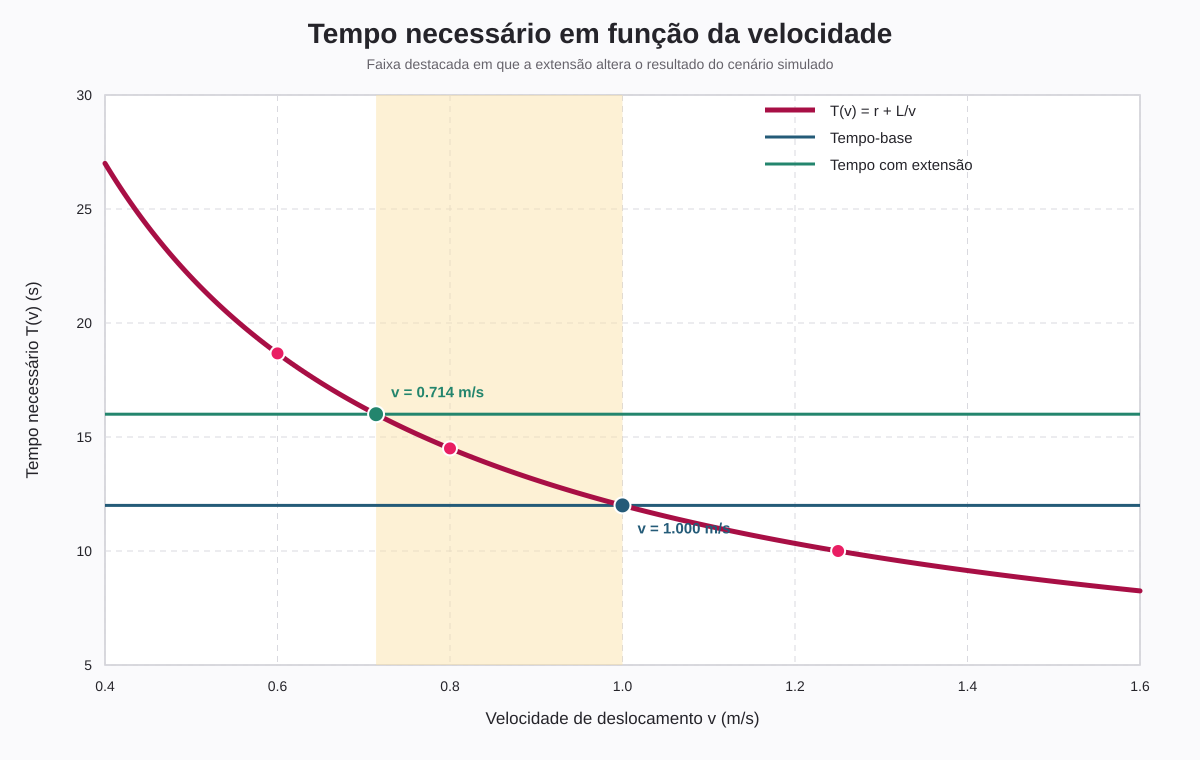

In [9]:
figura = grafico_tempo(cenario, pasta_graficos, 0.4, 1.6)
# O SVG é incorporado à saída da célula, dentro do próprio notebook.
display(SVG(data=figura.read_text(encoding="utf-8")))

**Leitura do gráfico.** A extensão de 4 s reduz o limiar de 1 para 0,714286 m/s. Para 0,8 m/s, a margem muda de −2,5 s para +1,5 s. Para 0,6 m/s, os 16 s ainda são insuficientes. A faixa destacada é $0{,}714286\le v<1$ m/s. Estar exatamente sobre a fronteira significa margem zero.

### Limites do modelo

$$\lim_{v\to0^+}T(v)=+\infty,\qquad \lim_{v\to+\infty}T(v)=r=2\text{ s}.$$

Quando $v$ se aproxima de zero, a parcela $L/v$ cresce sem limite. Quando $v$ cresce, ela se aproxima de zero. A velocidade zero não pertence ao domínio; o limite no infinito é uma propriedade matemática, não uma velocidade humana possível. A tabela seguinte ilustra tendências, sem substituir a demonstração.

In [10]:
mostrar_tabela(["v (m/s)", "T(v) (s)"], [
    [v, f"{tempo_necessario_s(v, cenario):.6f}"]
    for v in (0.001, 0.01, 0.1, 1, 10, 1000)
])

v (m/s),T(v) (s)
0.001,10002.000000
0.01,1002.000000
0.1,102.000000
1,12.000000
10,3.000000
1000,2.010000


## 3. Derivadas e sensibilidade

Derivando com $L$ e $r$ constantes:

$$T(v)=r+Lv^{-1},\quad T'(v)=-Lv^{-2},\quad T''(v)=2Lv^{-3}.$$

$T'<0$ indica redução do tempo com aumento da velocidade. $T''>0$ demonstra convexidade: a mesma redução de velocidade exige um aumento de tempo maior nas velocidades menores. As unidades de $T'$ e $T''$ são s²/m e s³/m².

In [11]:
def derivada_tempo(velocidade_m_s: float, cenario: CenarioTravessia) -> float:
    """Calcula T'(v) = -L/v²."""

    if velocidade_m_s <= 0:
        raise ValueError("A velocidade deve ser positiva.")
    return -cenario.largura_m / velocidade_m_s**2


def segunda_derivada_tempo(velocidade_m_s: float, cenario: CenarioTravessia) -> float:
    """Calcula T''(v) = 2L/v³."""

    if velocidade_m_s <= 0:
        raise ValueError("A velocidade deve ser positiva.")
    return 2 * cenario.largura_m / velocidade_m_s**3

In [12]:
mostrar_tabela(["v (m/s)", "T′ (s²/m)", "T″ (s³/m²)"], [
    [v, f"{derivada_tempo(v, cenario):.4f}", f"{segunda_derivada_tempo(v, cenario):.4f}"]
    for v in (0.6, 0.8, 1.0)
])
for inicial, final in [(1.2, 1.1), (0.8, 0.7)]:
    aumento = tempo_necessario_s(final, cenario) - tempo_necessario_s(inicial, cenario)
    print(f"Redução de {inicial} para {final} m/s: +{aumento:.6f} s.")

v (m/s),T′ (s²/m),T″ (s³/m²)
0.6,-27.7778,92.5926
0.8,-15.6250,39.0625
1.0,-10.0000,20.0000


Redução de 1.2 para 1.1 m/s: +0.757576 s.
Redução de 0.8 para 0.7 m/s: +1.785714 s.


In [13]:
def grafico_derivadas(cenario: CenarioTravessia, pasta: Path, v_min: float, v_max: float) -> Path:
    """Figura 2: apresenta a taxa de variação e a convexidade de T(v)."""
    area_1 = AreaGrafico(105, 105, 1035, 245, v_min, v_max, -65, 0)
    area_2 = AreaGrafico(105, 435, 1035, 245, v_min, v_max, 0, 330)
    elementos: list[str] = []
    desenhar_eixos(elementos, area_1, valores_entre(v_min, v_max, 7), [-60, -45, -30, -15, 0],
                   "", "T'(v)", casas_x=1)
    desenhar_eixos(elementos, area_2, valores_entre(v_min, v_max, 7), [0, 75, 150, 225, 300],
                   "Velocidade de deslocamento v (m/s)", "T''(v)", casas_x=1)
    velocidades = valores_entre(v_min, v_max, 350)
    elementos.append(polilinha_svg([(area_1.px(v), area_1.py(derivada_tempo(v, cenario))) for v in velocidades],
                                   COR_VINHO, 5))
    elementos.append(polilinha_svg([(area_2.px(v), area_2.py(segunda_derivada_tempo(v, cenario))) for v in velocidades],
                                   COR_AZUL, 5))
    elementos.append(texto_svg(120, 92, "Primeira derivada — taxa de variação", 19, ancora="start", peso="bold"))
    elementos.append(texto_svg(120, 422, "Segunda derivada — convexidade", 19, ancora="start", peso="bold"))
    elementos.append(texto_svg(1125, 325, "T'(v) < 0: velocidades maiores reduzem o tempo.",
                               15, ancora="end", cor=COR_VINHO, peso="bold"))
    elementos.append(texto_svg(1125, 470, "T''(v) > 0: maior sensibilidade nas velocidades menores.",
                               15, ancora="end", cor=COR_AZUL, peso="bold"))
    return salvar_svg(
        pasta / "02_derivadas_e_sensibilidade.svg",
        "Taxa de variação e sensibilidade do modelo",
        "A mesma redução de velocidade produz um aumento maior de tempo em velocidades menores",
        elementos,
    )

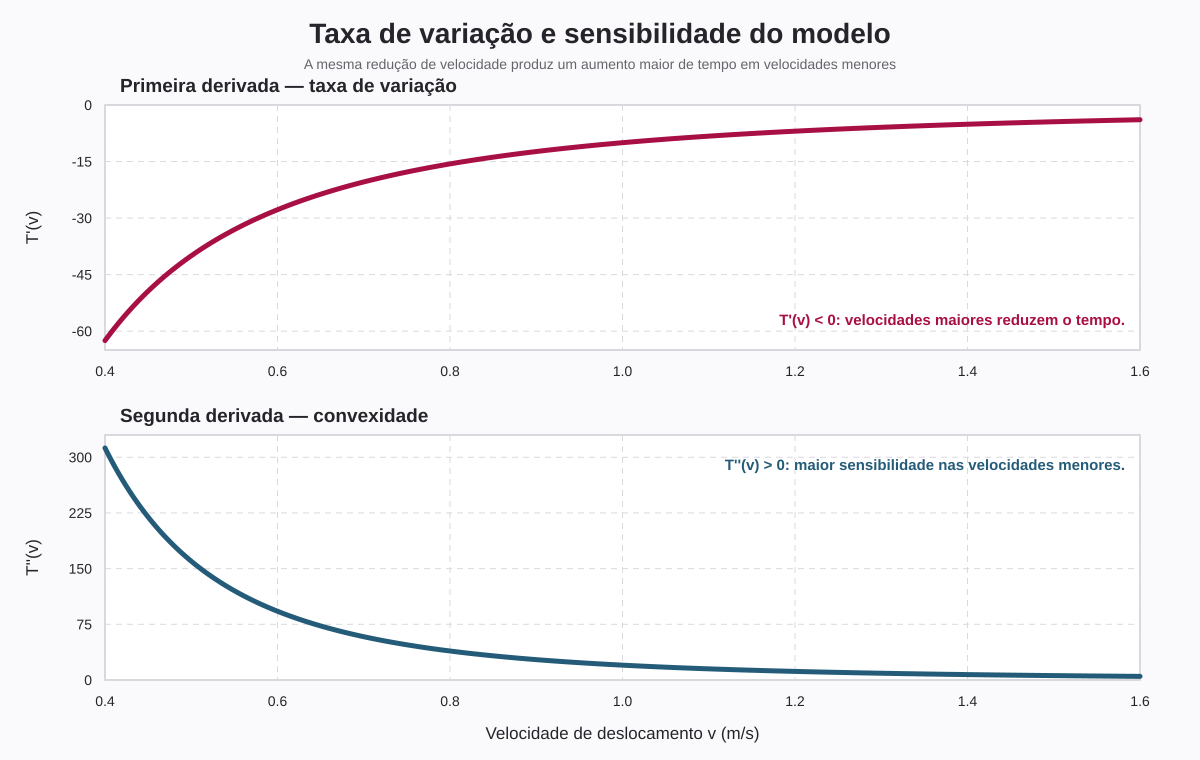

In [14]:
figura = grafico_derivadas(cenario, pasta_graficos, 0.4, 1.6)
# O SVG é incorporado à saída da célula, dentro do próprio notebook.
display(SVG(data=figura.read_text(encoding="utf-8")))

**Interpretação.** A redução de 1,2 para 1,1 m/s acrescenta aproximadamente 0,758 s. De 0,8 para 0,7 m/s, acrescenta 1,786 s. A derivada quantifica por que pequenas diferenças de velocidade podem ser relevantes para pessoas com deslocamento mais lento.

## 4. Integral da taxa de chegada

Modelamos uma taxa hipotética, em pedestres/s:

$$\lambda(t)=\lambda_0+\beta t=0{,}4+0{,}05t.$$

Uma primitiva é $N(t)=\lambda_0t+\beta t^2/2$. Pelo Teorema Fundamental do Cálculo:

$$\int_a^b\lambda(t)dt=\lambda_0(b-a)+\frac{\beta}{2}(b^2-a^2).$$

Para uma pessoa que chega no instante $t$, a conclusão exige $t+T(v)\le G+e$. A velocidade de referência é 1 m/s: ela precisa de 12 s. A janela adicional de chegadas vai de 0 a 4 s desde o início da fase, **não de 12 a 16 s**.

$$\int_0^4(0{,}4+0{,}05t)dt=[0{,}4t+0{,}025t^2]_0^4=2.$$

Conferimos a expressão analítica com trapézios. A função `integrar_trapezios` também será utilizada na integral do tempo.

In [15]:
def taxa_chegada_ped_s(instante_s: float, cenario: CenarioTravessia) -> float:
    """Calcula λ(t) = λ₀ + βt."""

    if not math.isfinite(instante_s) or instante_s < 0:
        raise ValueError("O instante deve ser não negativo e finito.")
    return cenario.taxa_inicial_ped_s + cenario.crescimento_taxa_ped_s2 * instante_s


def janela_adicional_s(cenario: CenarioTravessia) -> tuple[float, float]:
    """Retorna a janela de chegadas que passa a caber graças à extensão."""

    tempo = tempo_necessario_s(cenario.velocidade_referencia_m_s, cenario)
    limite_base = max(0.0, cenario.tempo_base_s - tempo)
    limite_estendido = max(0.0, cenario.tempo_estendido_s - tempo)
    return limite_base, limite_estendido


def chegadas_acumuladas_analitica(
    inicio_s: float,
    fim_s: float,
    cenario: CenarioTravessia,
) -> float:
    """Calcula exatamente a integral de λ(t) entre dois instantes."""

    validar_janela(inicio_s, fim_s)
    lambda_0 = cenario.taxa_inicial_ped_s
    beta = cenario.crescimento_taxa_ped_s2
    return lambda_0 * (fim_s - inicio_s) + beta * (fim_s**2 - inicio_s**2) / 2


def integrar_trapezios(
    funcao: Callable[[float, CenarioTravessia], float],
    inicio: float,
    fim: float,
    cenario: CenarioTravessia,
    pontos: int,
) -> float:
    """Integra uma função por trapézios; cada extremo recebe metade do peso."""
    if pontos < 2:
        raise ValueError("A integração numérica exige pelo menos dois pontos.")
    passo = (fim - inicio) / (pontos - 1)
    soma = (funcao(inicio, cenario) + funcao(fim, cenario)) / 2
    for indice in range(1, pontos - 1):
        soma += funcao(inicio + indice * passo, cenario)
    return soma * passo


def chegadas_acumuladas_numerica(
    inicio_s: float,
    fim_s: float,
    cenario: CenarioTravessia,
    pontos: int = 2001,
) -> float:
    """Valida a integral analítica pela regra numérica dos trapézios."""

    validar_janela(inicio_s, fim_s)
    if pontos < 2:
        raise ValueError("A integração numérica exige pelo menos dois pontos.")
    if math.isclose(inicio_s, fim_s):
        return 0.0

    return integrar_trapezios(taxa_chegada_ped_s, inicio_s, fim_s, cenario, pontos)

In [16]:
inicio, fim = janela_adicional_s(cenario)
integral_chegadas = chegadas_acumuladas_analitica(inicio, fim, cenario)
integral_chegadas_num = chegadas_acumuladas_numerica(inicio, fim, cenario)
print(f"Janela adicional de chegada: [{inicio:.3f}; {fim:.3f}] s")
print(f"Integral analítica: {integral_chegadas:.6f} chegadas esperadas")
print(f"Integral por trapézios: {integral_chegadas_num:.6f}")
print(f"Erro absoluto: {abs(integral_chegadas-integral_chegadas_num):.3e}")

Janela adicional de chegada: [0.000; 4.000] s
Integral analítica: 2.000000 chegadas esperadas
Integral por trapézios: 2.000000
Erro absoluto: 2.220e-16


In [17]:
def grafico_integral(cenario: CenarioTravessia, pasta: Path) -> Path:
    """Figura 3: destaca a integral de chegadas na janela adicional."""
    limite_t = cenario.tempo_estendido_s
    inicio, fim = janela_adicional_s(cenario)
    area = AreaGrafico(105, 95, 1035, 570, 0, limite_t, 0, 1.4)
    elementos: list[str] = []
    desenhar_eixos(elementos, area, [0, 2, 4, 6, 8, 10, 12, 14, 16],
                   [0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4],
                   "Instante desde o início da fase (s)", "Taxa λ(t) (pedestres/s)", casas_x=0, casas_y=1)
    # A área sob a taxa representa chegadas esperadas, não medições reais.
    instantes_janela = valores_entre(inicio, fim, 100)
    poligono = [(area.px(inicio), area.py(0))]
    poligono.extend((area.px(t), area.py(taxa_chegada_ped_s(t, cenario))) for t in instantes_janela)
    poligono.append((area.px(fim), area.py(0)))
    elementos.append(poligono_svg(poligono, "#FBE1A7", 0.82, "#E2B55C"))
    instantes = valores_entre(0, limite_t, 350)
    elementos.append(polilinha_svg([(area.px(t), area.py(taxa_chegada_ped_s(t, cenario))) for t in instantes],
                                   COR_VINHO, 5))
    elementos.append(linha_svg(area.px(inicio), area.y, area.px(inicio), area.y + area.altura,
                               COR_VERDE, 2, "8 6"))
    elementos.append(linha_svg(area.px(fim), area.y, area.px(fim), area.y + area.altura,
                               COR_VERDE, 2, "8 6"))
    acumulado = chegadas_acumuladas_analitica(inicio, fim, cenario)
    elementos.append(texto_svg(area.px((inicio + fim) / 2), area.py(0.18),
                               f"Integral = {acumulado:.3f} chegadas esperadas", 17, peso="bold"))
    elementos.append(texto_svg(1120, 120, "λ(t) = λ₀ + βt", 16, ancora="end", cor=COR_VINHO, peso="bold"))
    return salvar_svg(
        pasta / "03_integral_chegadas_acumuladas.svg",
        "Integral da taxa de chegada",
        "A área destacada representa a grandeza acumulada na janela adicional",
        elementos,
    )

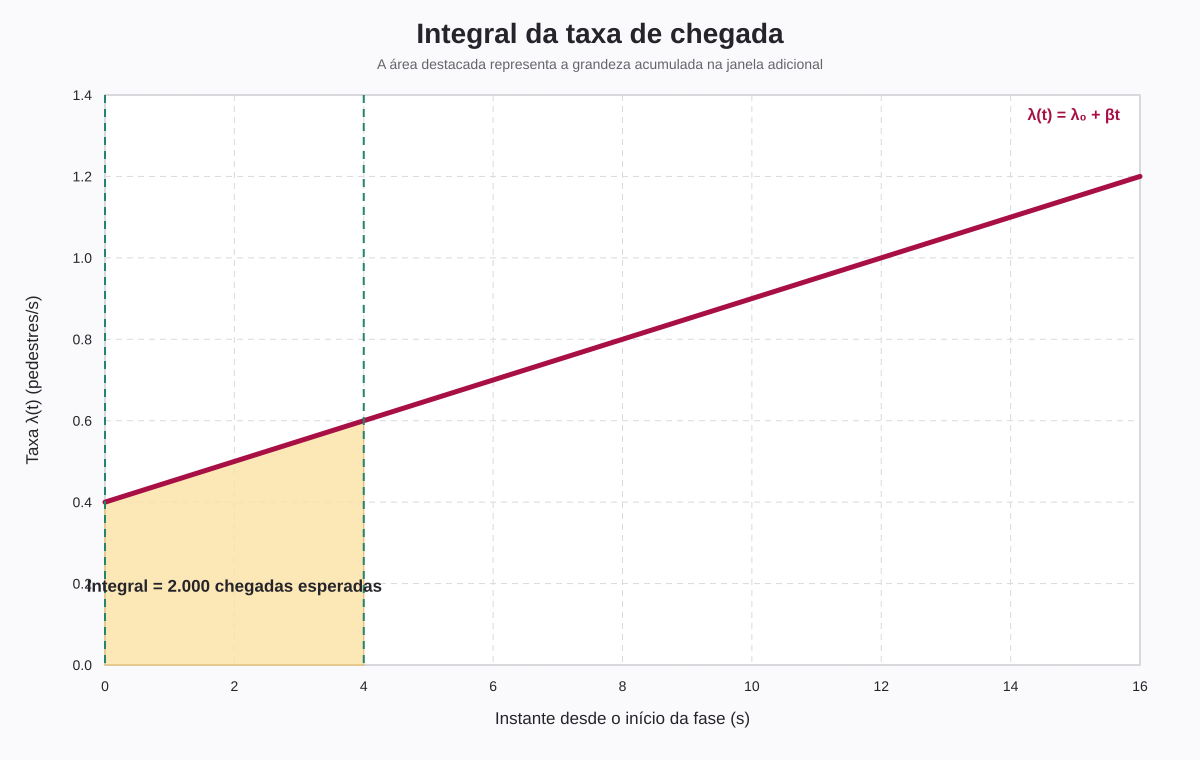

In [18]:
figura = grafico_integral(cenario, pasta_graficos)
# O SVG é incorporado à saída da célula, dentro do próprio notebook.
display(SVG(data=figura.read_text(encoding="utf-8")))

**Interpretação.** A área estima duas chegadas adicionais compatíveis com a duração estendida, sob as hipóteses adotadas. Não são duas pessoas observadas nem evidência de benefício em campo. A taxa é linear, por isso os trapézios reproduzem sua integral salvo arredondamento.

## 5. Mapa de decisão por largura e velocidade

Isolando a largura na condição de conclusão:

$$L\le v(G-r)\quad\text{ou}\quad L\le v(G+e-r).$$

As retas separam três regiões: conclusão no tempo-base, conclusão apenas com extensão e tempo ainda insuficiente. O código abaixo aplica essas inequações ao cenário de referência.

In [19]:
velocidade_exemplo = 0.8
largura_base = velocidade_exemplo * (cenario.tempo_base_s - cenario.tempo_reacao_s)
largura_estendida = velocidade_exemplo * (cenario.tempo_estendido_s - cenario.tempo_reacao_s)
print(f"Para v = {velocidade_exemplo} m/s:")
print(f"Largura máxima no tempo-base: {largura_base:.2f} m")
print(f"Largura máxima com extensão: {largura_estendida:.2f} m")

Para v = 0.8 m/s:
Largura máxima no tempo-base: 8.00 m
Largura máxima com extensão: 11.20 m


In [20]:
def grafico_mapa(cenario: CenarioTravessia, pasta: Path, v_min: float, v_max: float) -> Path:
    """Figura 4: classifica combinações de largura e velocidade."""
    l_min, l_max = 4.0, max(16.0, cenario.largura_m * 1.5)
    area = AreaGrafico(105, 95, 1035, 570, v_min, v_max, l_min, l_max)
    elementos: list[str] = []
    desenhar_eixos(elementos, area, valores_entre(v_min, v_max, 7), [4, 6, 8, 10, 12, 14, 16],
                   "Velocidade de deslocamento v (m/s)", "Largura da travessia L (m)", casas_x=1)
    velocidades = valores_entre(v_min, v_max, 300)
    def fronteira(tempo_disponivel: float) -> list[tuple[float, float]]:
        """Calcula a largura-limite e recorta a curva para caber nos eixos."""
        pontos = []
        for velocidade in velocidades:
            largura_limite = velocidade * (tempo_disponivel - cenario.tempo_reacao_s)
            largura_visivel = min(l_max, max(l_min, largura_limite))
            pontos.append((area.px(velocidade), area.py(largura_visivel)))
        return pontos

    base = fronteira(cenario.tempo_base_s)
    estendida = fronteira(cenario.tempo_estendido_s)

    verde = [(area.px(v_min), area.py(l_min)), (area.px(v_max), area.py(l_min)), *reversed(base)]
    amarelo = [*base, *reversed(estendida)]
    vermelho = [*estendida, (area.px(v_max), area.py(l_max)), (area.px(v_min), area.py(l_max))]
    elementos.append(poligono_svg(vermelho, "#F3B8B8", 0.9))
    elementos.append(poligono_svg(amarelo, "#FBE1A7", 0.9))
    elementos.append(poligono_svg(verde, "#B9E1D3", 0.9))
    elementos.append(polilinha_svg(base, COR_AZUL, 4))
    elementos.append(polilinha_svg(estendida, COR_VERDE, 4))
    elementos.append(circulo_svg(area.px(cenario.velocidade_referencia_m_s), area.py(cenario.largura_m),
                                 9, COR_VINHO))
    elementos.append(texto_svg(125, 125, "Verde: conclui no tempo-base", 15, ancora="start", peso="bold"))
    elementos.append(texto_svg(125, 151, "Amarelo: conclui somente com extensão", 15, ancora="start", peso="bold"))
    elementos.append(texto_svg(125, 177, "Vermelho: tempo ainda insuficiente", 15, ancora="start", peso="bold"))
    return salvar_svg(
        pasta / "04_mapa_decisao.svg",
        "Mapa de decisão por largura e velocidade",
        "Comparação dos resultados com 12 segundos e com a extensão até 16 segundos",
        elementos,
    )

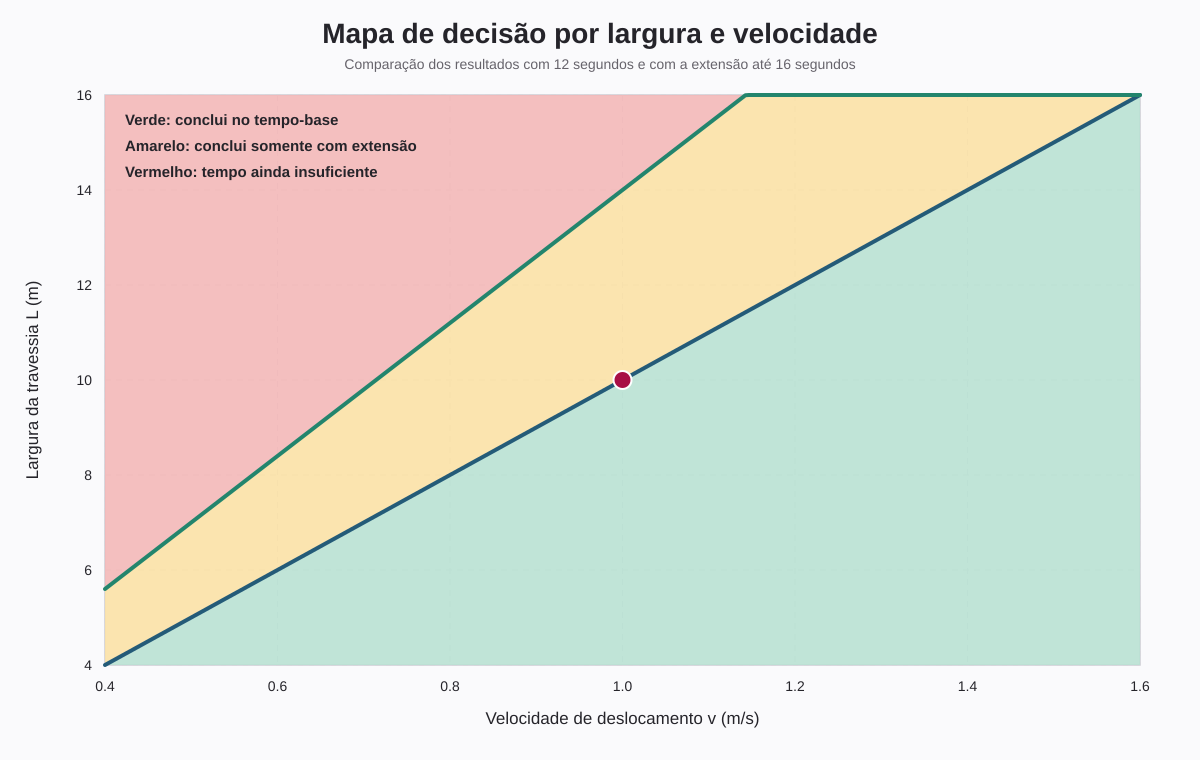

In [21]:
figura = grafico_mapa(cenario, pasta_graficos, 0.4, 1.6)
# O SVG é incorporado à saída da célula, dentro do próprio notebook.
display(SVG(data=figura.read_text(encoding="utf-8")))

**Interpretação.** Para 0,8 m/s, o limite aumenta de 8 m para 11,2 m. A faixa de 10 m pertence à região amarela. Com 0,6 m/s, a largura máxima com extensão é 8,4 m, e a faixa de 10 m permanece na região vermelha. As cores expressam as inequações; não certificam segurança viária.

## 6. Tempo médio por integral definida

O valor médio de uma função em $[a,b]$ é:

$$\overline T=\frac{1}{b-a}\int_a^bT(v)dv.$$

Integrando cada parcela:

$$\int_a^b\left(r+\frac Lv\right)dv=r(b-a)+L\ln\left(\frac ba\right).$$

Adotamos $a=0{,}6$ e $b=1{,}25$ m/s. A integral tem unidade s·(m/s); dividir por $b-a$, em m/s, fornece segundos. A razão $b/a$ é adimensional.

In [22]:
def intervalo_velocidades_cenario(cenario: CenarioTravessia) -> tuple[float, float]:
    """Obtém uma faixa não degenerada para a análise integral das velocidades."""

    inicio = min(cenario.velocidades_m_s)
    fim = max(cenario.velocidades_m_s)
    if math.isclose(inicio, fim):
        inicio = 0.8 * inicio
        fim = 1.2 * fim
    return inicio, fim


def integral_tempo_por_velocidade(
    velocidade_inicial_m_s: float,
    velocidade_final_m_s: float,
    cenario: CenarioTravessia,
) -> float:
    """Calcula ∫T(v)dv = r(b-a) + L ln(b/a), para 0 < a < b."""

    validar_intervalo_velocidade(velocidade_inicial_m_s, velocidade_final_m_s)
    a, b = velocidade_inicial_m_s, velocidade_final_m_s
    return cenario.tempo_reacao_s * (b - a) + cenario.largura_m * math.log(b / a)


def integral_tempo_numerica(
    velocidade_inicial_m_s: float,
    velocidade_final_m_s: float,
    cenario: CenarioTravessia,
    pontos: int = 4001,
) -> float:
    """Valida a integral de T(v) pela regra composta dos trapézios."""

    validar_intervalo_velocidade(velocidade_inicial_m_s, velocidade_final_m_s)
    return integrar_trapezios(
        tempo_necessario_s, velocidade_inicial_m_s, velocidade_final_m_s, cenario, pontos
    )


def tempo_medio_no_intervalo(
    velocidade_inicial_m_s: float,
    velocidade_final_m_s: float,
    cenario: CenarioTravessia,
) -> float:
    """Calcula o valor médio de T(v) em um intervalo de velocidades."""

    integral = integral_tempo_por_velocidade(
        velocidade_inicial_m_s, velocidade_final_m_s, cenario
    )
    return integral / (velocidade_final_m_s - velocidade_inicial_m_s)

In [23]:
a, b = intervalo_velocidades_cenario(cenario)
integral_tempo = integral_tempo_por_velocidade(a, b, cenario)
integral_tempo_num = integral_tempo_numerica(a, b, cenario)
tempo_medio = tempo_medio_no_intervalo(a, b, cenario)
print(f"Intervalo: [{a:.2f}; {b:.2f}] m/s")
print(f"Integral: {integral_tempo:.6f} s·(m/s)")
print(f"Erro dos trapézios: {abs(integral_tempo-integral_tempo_num):.3e}")
print(f"Valor médio: {tempo_medio:.6f} s")

Intervalo: [0.60; 1.25] m/s
Integral: 8.639692 s·(m/s)
Erro dos trapézios: 4.704e-08
Valor médio: 13.291833 s


In [24]:
def grafico_tempo_medio_integral(cenario: CenarioTravessia, pasta: Path) -> Path:
    """Figura 5: compara T(v) ao seu valor médio uniforme no intervalo."""
    inicio, fim = intervalo_velocidades_cenario(cenario)
    # A média dá peso igual a todas as velocidades do intervalo.
    media = tempo_medio_no_intervalo(inicio, fim, cenario)
    y_max = math.ceil(tempo_necessario_s(inicio, cenario) * 1.18 / 5) * 5
    area = AreaGrafico(105, 95, 1035, 570, inicio, fim, 0, y_max)
    elementos: list[str] = []
    desenhar_eixos(
        elementos,
        area,
        valores_entre(inicio, fim, 7),
        valores_entre(0, y_max, 6),
        "Velocidade considerada v (m/s)",
        "Tempo necessário T(v) (s)",
        casas_x=2,
        casas_y=0,
    )
    velocidades = valores_entre(inicio, fim, 350)
    curva = [(area.px(v), area.py(tempo_necessario_s(v, cenario))) for v in velocidades]
    preenchimento = [(area.px(inicio), area.py(0)), *curva, (area.px(fim), area.py(0))]
    elementos.append(poligono_svg(preenchimento, "#E8C4D2", 0.62, "#CF8DA5"))
    elementos.append(polilinha_svg(curva, COR_VINHO, 5))
    elementos.append(linha_svg(area.x, area.py(media), area.x + area.largura, area.py(media),
                               COR_VERDE, 4, "10 7"))
    elementos.append(texto_svg(1120, area.py(media) - 12,
                               f"Valor médio = {media:.3f} s", 16, ancora="end",
                               cor=COR_VERDE, peso="bold"))
    integral = integral_tempo_por_velocidade(inicio, fim, cenario)
    elementos.append(texto_svg(125, 130,
                               f"∫ T(v)dv = {integral:.3f} s·(m/s)", 16,
                               ancora="start", peso="bold"))
    elementos.append(texto_svg(125, 157,
                               "T̄ = [1/(b-a)] ∫ T(v)dv", 16,
                               ancora="start", cor=COR_AZUL, peso="bold"))
    return salvar_svg(
        pasta / "05_tempo_medio_por_integral.svg",
        "Tempo médio de travessia por integral definida",
        "A área sob T(v) permite avaliar conjuntamente a faixa de velocidades simulada",
        elementos,
    )

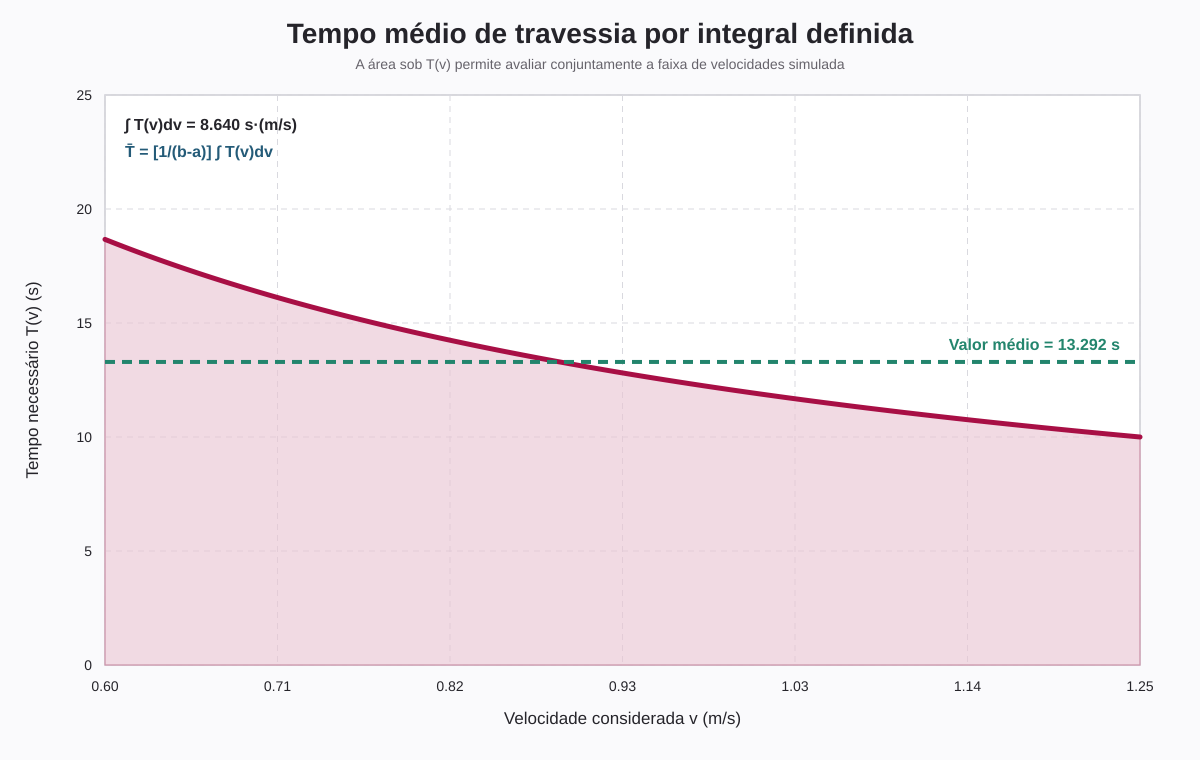

In [25]:
figura = grafico_tempo_medio_integral(cenario, pasta_graficos)
# O SVG é incorporado à saída da célula, dentro do próprio notebook.
display(SVG(data=figura.read_text(encoding="utf-8")))

**Interpretação.** A integral é aproximadamente 8,639692 s·(m/s), e o valor médio é 13,291833 s. Essa média dá peso uniforme às velocidades entre os extremos. Não é a média aritmética dos quatro cenários nem uma média populacional observada. Mesmo com 16 s acima da média, 0,6 m/s ainda exige 18,667 s.

## 7. Otimização da extensão

Construímos um índice didático que soma um impacto residual decrescente sobre pedestres e uma penalização viária crescente:

$$C(e)=Ae^{-ke}+Be^2,\quad e\ge0.$$

Aqui, $e$ é a extensão; a exponencial também pode ser escrita como $\exp(-ke)$. Os parâmetros são $A=100$ pontos, $k=0{,}35$ s⁻¹ e $B=2$ pontos/s².

$$C'(e)=-Ak\exp(-ke)+2Be,\qquad C''(e)=Ak^2\exp(-ke)+2B>0.$$

Como $C'(0)<0$, a derivada cresce e eventualmente se torna positiva, existe uma única raiz de $C'$. A convexidade confirma um mínimo global. Além disso, $C(0)=A$ e $C(e)\to+\infty$ quando $e\to+\infty$.

O código usa **bisseção**: encontra extremos com sinais diferentes da derivada e reduz o intervalo à metade sucessivamente. A tolerância numérica não é uma precisão física de controle semafórico.

In [26]:
def custo_acessibilidade(extensao_s: float, cenario: CenarioTravessia) -> float:
    """Índice decrescente do impacto sobre pedestres: A·exp(-k·e)."""

    validar_extensao(extensao_s)
    return cenario.peso_acessibilidade * math.exp(
        -cenario.decaimento_beneficio_s_inv * extensao_s
    )


def custo_impacto_viario(extensao_s: float, cenario: CenarioTravessia) -> float:
    """Índice crescente do impacto veicular: B·e²."""

    validar_extensao(extensao_s)
    return cenario.peso_impacto_viario * extensao_s**2


def custo_total_extensao(extensao_s: float, cenario: CenarioTravessia) -> float:
    """Soma os índices de acessibilidade e impacto viário."""
    return custo_acessibilidade(extensao_s, cenario) + custo_impacto_viario(extensao_s, cenario)


def derivada_custo_total(extensao_s: float, cenario: CenarioTravessia) -> float:
    """Calcula C'(e) para localizar o ponto de custo total mínimo."""

    validar_extensao(extensao_s)
    a = cenario.peso_acessibilidade
    k = cenario.decaimento_beneficio_s_inv
    b = cenario.peso_impacto_viario
    return -a * k * math.exp(-k * extensao_s) + 2 * b * extensao_s


def segunda_derivada_custo_total(extensao_s: float, cenario: CenarioTravessia) -> float:
    """Calcula C''(e); seu valor positivo confirma a convexidade do modelo."""

    validar_extensao(extensao_s)
    a = cenario.peso_acessibilidade
    k = cenario.decaimento_beneficio_s_inv
    b = cenario.peso_impacto_viario
    return a * k**2 * math.exp(-k * extensao_s) + 2 * b


def extensao_otima_s(cenario: CenarioTravessia, tolerancia: float = 1e-10) -> float:
    """Resolve C'(e)=0 por bisseção, sem depender de bibliotecas externas."""

    if tolerancia <= 0:
        raise ValueError("A tolerância deve ser positiva.")
    if derivada_custo_total(0.0, cenario) >= 0:
        return 0.0
    # Encontramos extremos com sinais diferentes da derivada do custo.
    limite_superior = max(1.0, cenario.extensao_s)
    while derivada_custo_total(limite_superior, cenario) < 0:
        limite_superior *= 2
        if limite_superior > LIMITE_BUSCA_EXTENSAO_S:
            raise RuntimeError("Não foi possível limitar a raiz da função de custo.")
    # A convexidade permite descartar metade do intervalo a cada passo.
    inferior = 0.0
    while limite_superior - inferior > tolerancia:
        meio = (inferior + limite_superior) / 2
        if derivada_custo_total(meio, cenario) < 0:
            inferior = meio
        else:
            limite_superior = meio
    return (inferior + limite_superior) / 2

In [27]:
otima = extensao_otima_s(cenario)
mostrar_tabela(["Indicador", "Resultado"], [
    ["Extensão no mínimo", f"{otima:.6f} s"],
    ["Custo no mínimo", f"{custo_total_extensao(otima, cenario):.6f} pontos"],
    ["Custo com 4 s", f"{custo_total_extensao(cenario.extensao_s, cenario):.6f} pontos"],
    ["Derivada no mínimo", f"{derivada_custo_total(otima, cenario):.3e} pontos/s"],
    ["Segunda derivada", f"{segunda_derivada_custo_total(otima, cenario):.6f} pontos/s²"],
])

Indicador,Resultado
Extensão no mínimo,3.029987 s
Custo no mínimo,52.990063 pontos
Custo com 4 s,56.659696 pontos
Derivada no mínimo,-7.810e-11 pontos/s
Segunda derivada,8.241982 pontos/s²


In [28]:
def grafico_otimizacao_extensao(cenario: CenarioTravessia, pasta: Path) -> Path:
    """Figura 6: apresenta os custos, o mínimo de C(e) e sua derivada."""
    # O mínimo depende de pesos didáticos, não garante atender todos.
    otima = extensao_otima_s(cenario)
    limite = max(8.0, cenario.extensao_s * 2, otima * 2)
    extensoes = valores_entre(0, limite, 400)
    custos_pedestre = [custo_acessibilidade(e, cenario) for e in extensoes]
    custos_viario = [custo_impacto_viario(e, cenario) for e in extensoes]
    custos_totais = [custo_total_extensao(e, cenario) for e in extensoes]
    derivadas = [derivada_custo_total(e, cenario) for e in extensoes]

    y_max = math.ceil(max(*custos_pedestre, *custos_viario, *custos_totais) / 20) * 20
    d_min = math.floor(min(derivadas) / 10) * 10
    d_max = math.ceil(max(derivadas) / 10) * 10
    area_custo = AreaGrafico(105, 95, 1035, 430, 0, limite, 0, y_max)
    area_derivada = AreaGrafico(105, 640, 1035, 145, 0, limite, d_min, d_max)
    marcas_x = valores_entre(0, limite, 6)
    elementos: list[str] = []
    desenhar_eixos(
        elementos, area_custo, marcas_x, valores_entre(0, y_max, 6),
        "", "Índice de impacto", casas_x=1, casas_y=0,
    )
    desenhar_eixos(
        elementos, area_derivada, marcas_x, [d_min, 0, d_max],
        "Extensão adicional e (s)", "C'(e)", casas_x=1, casas_y=0,
    )
    # Área, valores, cor e espessura de cada curva.
    curvas = [
        (area_custo, custos_pedestre, COR_VINHO, 4),
        (area_custo, custos_viario, COR_AZUL, 4),
        (area_custo, custos_totais, COR_VERDE, 6),
        (area_derivada, derivadas, COR_ROSA, 4),
    ]
    for area, valores, cor, espessura in curvas:
        pontos = [(area.px(e), area.py(valor)) for e, valor in zip(extensoes, valores)]
        elementos.append(polilinha_svg(pontos, cor, espessura))
    x_otima_custo = area_custo.px(otima)
    x_otima_derivada = area_derivada.px(otima)
    elementos.append(linha_svg(x_otima_custo, area_custo.y, x_otima_custo,
                               area_custo.y + area_custo.altura, COR_VERDE, 2, "8 6"))
    elementos.append(linha_svg(x_otima_derivada, area_derivada.y, x_otima_derivada,
                               area_derivada.y + area_derivada.altura, COR_VERDE, 2, "8 6"))
    elementos.append(circulo_svg(x_otima_custo, area_custo.py(custo_total_extensao(otima, cenario)),
                                 9, COR_VERDE))
    elementos.append(circulo_svg(x_otima_derivada, area_derivada.py(0), 8, COR_ROSA))
    x_atual = area_custo.px(min(cenario.extensao_s, limite))
    elementos.append(linha_svg(x_atual, area_custo.y, x_atual,
                               area_custo.y + area_custo.altura, COR_AMARELO, 3, "5 5"))
    elementos.append(texto_svg(x_atual + 10, 500, f"Atual: {cenario.extensao_s:.2f} s",
                               14, ancora="start", cor="#9A6510", peso="bold"))
    elementos.extend([
        linha_svg(750, 118, 800, 118, COR_VINHO, 4),
        texto_svg(815, 124, "Impacto sobre pedestres", 14, ancora="start"),
        linha_svg(750, 145, 800, 145, COR_AZUL, 4),
        texto_svg(815, 151, "Impacto viário", 14, ancora="start"),
        linha_svg(750, 172, 800, 172, COR_VERDE, 6),
        texto_svg(815, 178, "Custo total C(e)", 14, ancora="start"),
        texto_svg(125, 125, f"Mínimo em e = {otima:.3f} s", 16,
                  ancora="start", cor=COR_VERDE, peso="bold"),
        texto_svg(125, 153, "C'(e) = 0 e C''(e) > 0", 15,
                  ancora="start", peso="bold"),
        texto_svg(120, 625, "Derivada do custo total — mudança de sinal no ponto ótimo",
                  18, ancora="start", peso="bold"),
    ])
    return salvar_svg(
        pasta / "06_otimizacao_extensao.svg",
        "Otimização matemática da extensão do sinal",
        "Equilíbrio simulado entre benefício de acessibilidade e impacto no fluxo viário",
        elementos,
        altura=880,
    )

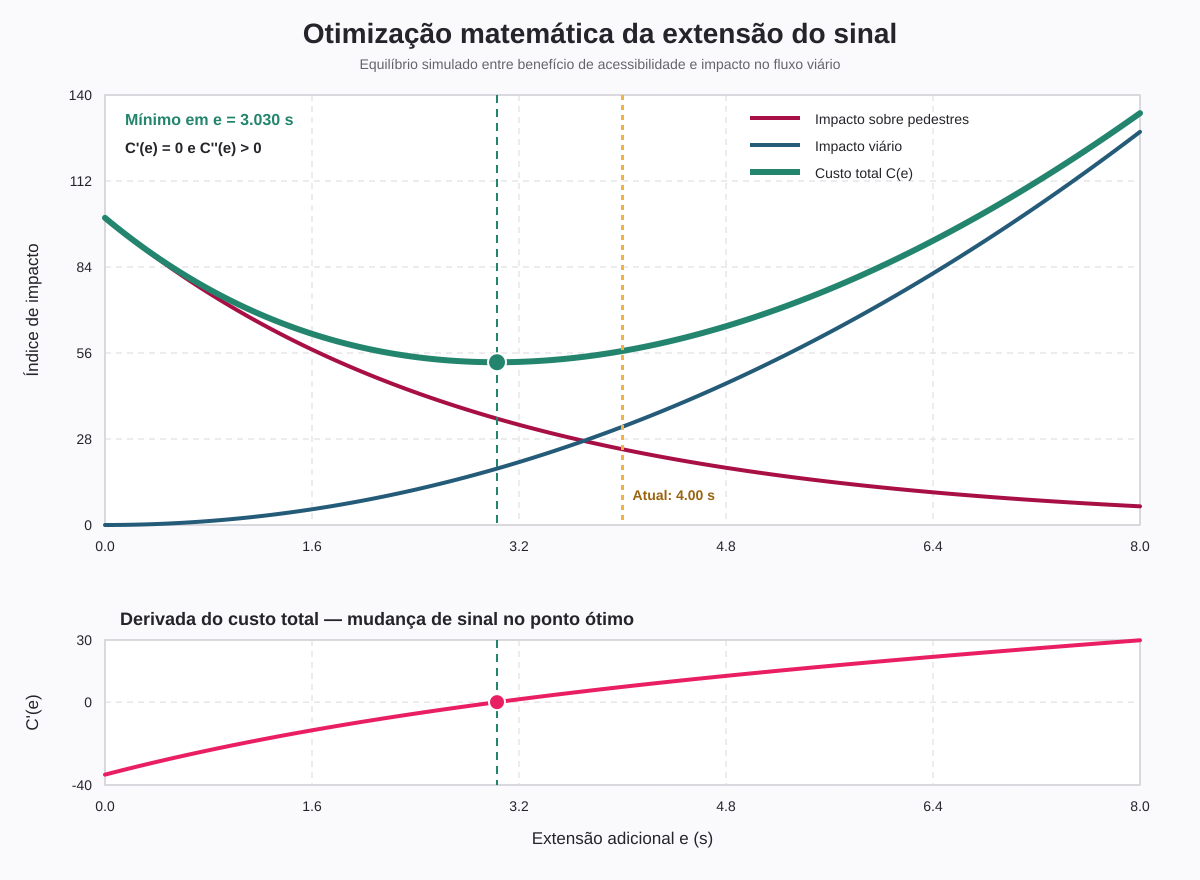

In [29]:
figura = grafico_otimizacao_extensao(cenario, pasta_graficos)
# O SVG é incorporado à saída da célula, dentro do próprio notebook.
display(SVG(data=figura.read_text(encoding="utf-8")))

**Interpretação.** O mínimo ocorre em aproximadamente 3,030 s e depende dos pesos escolhidos. Os índices não são atrasos medidos ou probabilidades de acidente. O tempo total seria aproximadamente 15,030 s, ainda insuficiente para 0,6 m/s.

Se acrescentássemos uma restrição de atendimento a essa velocidade, teríamos $e\ge\max(0,T(0{,}6)-G)=6{,}666667$ s. Essa restrição **não faz parte** da otimização implementada: é uma interpretação complementar que mostra por que um índice mínimo não substitui uma exigência de atendimento.

## 8. Conferência e conclusão

As verificações seguintes confrontam os métodos de integração, o sinal das derivadas e o ponto mínimo. Validam a consistência do cálculo; não demonstram que o cenário representa uma via real.

In [30]:
checagens = {
    "Integral de chegadas: analítica ≈ numérica": math.isclose(integral_chegadas, integral_chegadas_num, abs_tol=1e-9),
    "Integral do tempo: analítica ≈ numérica": math.isclose(integral_tempo, integral_tempo_num, abs_tol=1e-6),
    "Derivada de T negativa nos cenários": all(derivada_tempo(v, cenario) < 0 for v in cenario.velocidades_m_s),
    "Segunda derivada de T positiva": all(segunda_derivada_tempo(v, cenario) > 0 for v in cenario.velocidades_m_s),
    "C′ próxima de zero no mínimo": abs(derivada_custo_total(otima, cenario)) < 1e-8,
    "C″ positiva no mínimo": segunda_derivada_custo_total(otima, cenario) > 0,
    "Custo mínimo menor que custo configurado": custo_total_extensao(otima, cenario) <= custo_total_extensao(cenario.extensao_s, cenario) + 1e-9,
    "Seis gráficos gerados": len(list(pasta_graficos.glob("*.svg"))) == 6,
}
mostrar_tabela(["Verificação", "Resultado"], [[nome, "OK" if ok else "Investigar"] for nome, ok in checagens.items()])
assert all(checagens.values()), "Revise as verificações e os parâmetros."

Verificação,Resultado
Integral de chegadas: analítica ≈ numérica,OK
Integral do tempo: analítica ≈ numérica,OK
Derivada de T negativa nos cenários,OK
Segunda derivada de T positiva,OK
C′ próxima de zero no mínimo,OK
C″ positiva no mínimo,OK
Custo mínimo menor que custo configurado,OK
Seis gráficos gerados,OK


### Conclusão

No cenário padrão, aumentar a duração de 12 para 16 s reduz a velocidade mínima de 1,000 para 0,714286 m/s. A extensão muda a situação de alguns cenários, mas não atende a todos. As derivadas explicam a sensibilidade, os limites esclarecem o domínio e as integrais quantificam chegadas e um valor médio teórico.

A otimização demonstra um compromisso entre índices ilustrativos. Sua solução não é uma configuração validada para sinalização pública. Não há medições de campo, calibração dos pesos nem representação de filas e conflitos viários.

### Registro de apoio de IA

ChatGPT/Codex auxiliou na implementação, refatoração, organização do notebook e conferência computacional. Os pedidos incluíram organizar os cálculos, preservar os gráficos e criar uma versão em células semelhante à estrutura de um exercício do professor. Os resultados foram comparados com a versão `.py` e as células foram executadas em sequência. A revisão acadêmica e a apresentação cabem aos integrantes.

O exemplo do professor foi utilizado como referência de organização. O tema, as hipóteses e os cálculos deste notebook pertencem ao Passaí.